# Finite Elements for Contaminant Transport

## Problem description
In this notebook, code is provided to solve the advection/diffusion/reaction equation for transport of a contaminant in groundwater after an industrial spill. We consider an underground sand channel as aquifer. The aquifer is a buried meandering river and therefore has an irregular shape over which an unstructured mesh is needed. In the middle of the sand river, there is a clay island which is considered impermeable and splits the channel into two arms that again merge downstream. The aquifer in modeled in 2D, as a horizontal section, which implies uniform thickness of the aquifer and a planar flow profile. 

The advection/diffusion/reaction equation is given by:

$$
\frac{\partial c}{\partial t} = \kappa \nabla\cdot\nabla c - \mathbf{v}\cdot\nabla c - r c
$$

Where 
- $c$ is the unknown concentration field, dependent on space ($x$, $y$) and time ($t$)
- $\kappa$ is the diffusivity, assumed to be constant
- $\mathbf{v}$ is the groundwater velocity, satisfying $\nabla\cdot \mathbf{v} = 0$
- $r$ is a reaction rate, representing exponential decay of the contaminant

We use $\nabla a$ for the gradient of the scalar (results in a vector), and $\nabla\cdot\mathbf{q}$ for the divergence of a vector $\mathbf{q}$ (results in a scalar):

$$
\nabla c = \begin{bmatrix} \partial c/\partial x \\ \partial c/\partial y \end{bmatrix}, \qquad 
\nabla \cdot \mathbf{q} = \frac{\partial q_x}{\partial x} + \frac{\partial q_y}{\partial y}
$$

The two-dimensional domain $\Omega$ has a boundary $\Gamma$ that can be subdivided in a part where Dirichlet boundary conditions are applied $\Gamma_D$ and a part where Neumann boundary conditions are applied $\Gamma_N$. The Neumann boundary conditions define a contaminant flux of magnitude $q(x,y,t)$ into the domain:

$$
\kappa\nabla c\cdot \mathbf{n} = q
$$

where $\mathbf{n}$ is the outward pointing normal to the boundary. 

> **Task 1**
>
> To solve the problem finite element discretization is applied in 2D space, while time is discretized with backward Euler time stepping. A semi-discrete form is obtained by applying the finite element discretization, while leaving the time derivative untouched. The semi-discrete form for this problem is:
>
> $$
> \mathbf{M}\frac{\partial\mathbf{c}}{\partial t} + \mathbf{Kc} + \mathbf{Cc} + \mathbf{Rc} = \mathbf{f}
> $$
>
> where $\mathbf{M}$, $\mathbf{K}$, $\mathbf{C}$ and $\mathbf{R}$ are matrices and $\mathbf{c}$ is a vector with concentration values at the nodes. For now, $\mathbf{c}$ is still a continuous function of time.
>
> Starting from the strong form of the advection/diffusion/reaction equation, derive expressions for finite element matrices $\mathbf{M}$, $\mathbf{K}$, $\mathbf{C}$ and $\mathbf{R}$.
>
> **Hint:**
>
> - The matrix $\mathbf{K}$ should have the same form as the matrix for the 2D Poisson equation as derived [in the book](https://mude.citg.tudelft.nl/book/2026/fem/poisson2d.html) (except that $\kappa$ takes the place of $\nu$).
> - The concentration depends on time and space $c \equiv c(x,y,t)$. Spatial discretization is done with finite element shape functions, while time-dependence is in the nodal degrees of freedom: $c(x,y,t) = \mathbf{N}(x,y)\mathbf{c}(t)$.


## Load mesh and velocity field

The domain of interest is an aquifer, with embedded impermeable object. Only the permeable domain is meshed, resulting in a non-trivial geometry that is discretized with triangular elements. In the code block below, the provided mesh file is read using code from *mesh_utils.py*. A precomputed velocity field is also read from file. The velocity field is visualized on the mesh with a function from *postprocess.py*. The impermeable object appears as a gap in the mesh. 

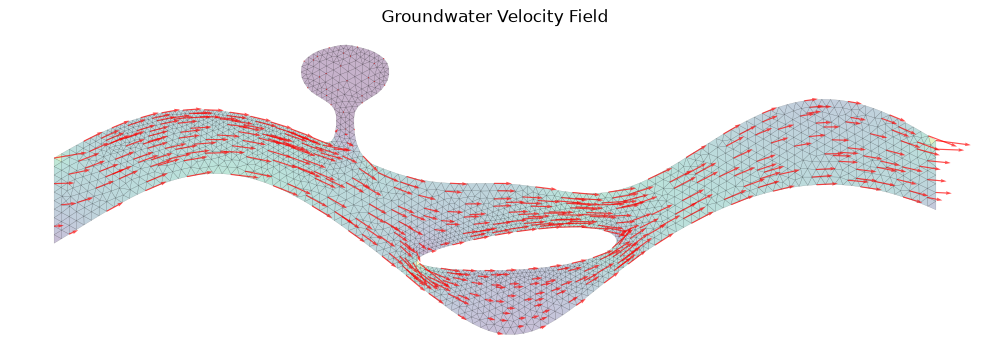

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
import os
from urllib.request import urlretrieve

# import local py-files
import postprocess as pp
import mesh_utils as mu

%matplotlib inline

# Download mesh and data files
def findfile(fname):
    if not os.path.isfile(fname):
        print(f"Downloading {fname}...")
        urlretrieve('https://github.com/TUDelft-MUDE/source-files/raw/main/file/GA2.2/'+fname, fname)

findfile('channel_aquifer.msh')
findfile('velocity_elems_channel.csv')

# Read mesh file
nodes, connectivity, edge_connectivity = mu.read_gmsh('channel_aquifer.msh')

# Load eleemnt-wise velocity field and visualize it on the mesh
velocities = np.loadtxt('velocity_elems_channel.csv', delimiter=',')
pp.plot_velocity_field(nodes, connectivity, velocities, scale_factor = 2e8 )



## Finite element functions

The main building blocks for the finite element simulation are provided in the code block below.

> **Task 2** 
>
> Look at how the different matrices are implemented and compare the implementations to the expressions you have derived. Only three of the four matrices $\mathbf{K}$, $\mathbf{R}$, $\mathbf{C}$ and $\mathbf{M}$ are defined here. Which of the three definitions can be used to also compute the missing one? 

In [3]:
# Function makes the coefficients of shape functions for a 3-node triangle with given node coordinates
def get_shape_functions_T3(n1, n2, n3):
    coordinate_matrix = np.ones((3,3))
    coeffs = np.zeros((3,3))
    
    coordinate_matrix[0, 1] = n1[0]
    coordinate_matrix[0, 2] = n1[1]
    coordinate_matrix[1, 1] = n2[0]
    coordinate_matrix[1, 2] = n2[1]
    coordinate_matrix[2, 1] = n3[0]
    coordinate_matrix[2, 2] = n3[1]
    
    c_inv = np.linalg.inv(coordinate_matrix)
    coeffs[0] = np.dot(c_inv, (1,0,0))
    coeffs[1] = np.dot(c_inv, (0,1,0))
    coeffs[2] = np.dot(c_inv, (0,0,1))
    
    return coeffs

# Function creates the derivative shape function vector (B) of the given 3-node triangle
def get_B_matrix(n1, n2, n3):
    coeffs = get_shape_functions_T3(n1, n2, n3)
    B_matrix = [[coeffs[0][1], coeffs[1][1], coeffs[2][1]], 
                [coeffs[0][2], coeffs[1][2], coeffs[2][2]]]
    return np.array(B_matrix)

# Function returns the area of the triangle
def get_area(n1, n2, n3):
    u = n3-n1
    v = n2-n1
    return abs(u[0]*v[1]-u[1]*v[0])/2

# Evaluate shape function matrix at given coordinates
def evaluate_N_matrix(ipcoords, n1, n2, n3):    
    coeffs = get_shape_functions_T3(n1, n2, n3)
    x = ipcoords[0]
    y = ipcoords[1]
    N_matrix = [[coeffs[0][0] + coeffs[0][1]*x + coeffs[0][2]*y, 
                 coeffs[1][0] + coeffs[1][1]*x + coeffs[1][2]*y, 
                 coeffs[2][0] + coeffs[2][1]*x + coeffs[2][2]*y]]
    return np.array(N_matrix)

# DIFFUSION: Function returns the K-matrix for a single element
def get_element_K(n1, n2, n3, nu):
    B = get_B_matrix(n1, n2, n3)
    element_area = get_area(n1, n2, n3)
    return element_area * nu * B.T @ B

# ADVECTION: Function returns the C-matrix for a single element
# Advection matrix using simple integration (assumes constant velocity in element)
def get_element_C(n1, n2, n3, velocity):
    B = get_B_matrix(n1, n2, n3)
    element_area = get_area(n1, n2, n3)
    centroid = (n1 + n2 + n3) / 3
    N_centroid = evaluate_N_matrix(centroid, n1, n2, n3)
    
    v_matrix = np.array(velocity).reshape((1,2))
    C_el = N_centroid.T @ v_matrix @ B * element_area
    
    return C_el

# MASS: Function returns the M-matrix for a single element
def get_element_M(n1, n2, n3):
    M_el = np.zeros((3,3))
    element_area = get_area(n1, n2, n3)    
    integration_locations = [(n1+n2)/2, (n2+n3)/2, (n3+n1)/2]
    integration_weights = [element_area/3, element_area/3, element_area/3]
    for x_ip, w_ip in zip(integration_locations, integration_weights):
        N_local = evaluate_N_matrix(x_ip, n1, n2, n3)
        M_el += N_local.T @ N_local * w_ip
    return M_el

# Assembly functions
def get_global_K(nodes, connectivity, nu):
    n_DOF = len(nodes)
    K = np.zeros((n_DOF, n_DOF))
    for elnodes in connectivity:
        K_el = get_element_K(nodes[elnodes[0]], nodes[elnodes[1]], nodes[elnodes[2]], nu)
        K[np.ix_(elnodes,elnodes)] += K_el
    return K

def get_global_C(nodes, connectivity, velocities):
    n_DOF = len(nodes)
    C = np.zeros((n_DOF, n_DOF))
    for elnodes, element_velocity in zip(connectivity, velocities):
        C_el = get_element_C(nodes[elnodes[0]], nodes[elnodes[1]], nodes[elnodes[2]], element_velocity)
        C[np.ix_(elnodes,elnodes)] += C_el
    return C

def get_global_M(nodes, connectivity):
    n_DOF = len(nodes)
    M = np.zeros((n_DOF, n_DOF))
    for elnodes in connectivity:
        M_el = get_element_M(nodes[elnodes[0]], nodes[elnodes[1]], nodes[elnodes[2]])
        M[np.ix_(elnodes,elnodes)] += M_el
    return M

def get_global_f(nodes, elems, q, xmin=-1e6, xmax=1e6):
    n_DOF = len(nodes)
    f = np.zeros(n_DOF)
    for elem in elems:
        xcentroid = ( nodes[elem[0]][0] + nodes[elem[1]][0] ) / 2
        if xcentroid > xmin and xcentroid < xmax:
            length = np.linalg.norm(nodes[elem[0]]-nodes[elem[1]])
            f[elem] += q*length/2
    return f


## Solve the time-dependent advection-diffusion-reaction problem

Euler backward time integration gives the following linear system of equations for solving $\mathbf{c}$ at $t=t_{n+1}$

$$ 
\left(\frac{1}{\Delta t} \mathbf{M}  + \mathbf{K} + \mathbf{C} + \mathbf{R} \right) \mathbf{c}_{n+1} = \frac{1}{\Delta t} \mathbf{M} \mathbf{c}_{n} + \mathbf{f}_{n+1}
$$ 

The system of equations is rewritten as

$$
\mathbf{K}^\mathrm{mod} \mathbf{c}_{n+1} = \mathbf{f}^\mathrm{mod}_{n+1}
$$

which is solved repeatedly in a loop over $n_t$ time steps. Because the system of equations needs to be solved $n_t$ times, each time with the same matrix $\mathbf{K^\mathrm{mod}}$ but a different right hand side vector $\mathbf{f}^\mathrm{mod}_{n+1}$, we use a two step approach for solving the system of equation. 

A system of equations $\mathbf{Ax}=\mathbf{b}$ can be solved in python in two lines as

```
  solver = sparse.linalg.factorized(A)
  x = solver(b)
```

Where the first line does most of the work associated with solving the system of equations, similar to but still cheaper than inverting the matrix. In our case, the first (expensive) line can be done outside of the loop over time steps, after which the second (cheap) line is all that needs to be done inside the loop. 

In [4]:
def simulate ( velocities,               # Velocity field [m/s]
               dt_days = 50,             # Time step size [days]
               nt = 3000,                # Number of time steps
               diffusivity = 2e-7,       # Diffusion coefficient [m^2/s]
               reaction_rate = 2e-10,    # Reaction rate [1/s]
               q_max = 2e-9,             # Maximum boundary flux [kg/m^2/s]
               C_initial = 0,            # Initial concentration [kg/m^3]
               period = 5000,            # Spill duration [days]              
               source_bounds = [60,100]  # Position of the spill [m]
             ):

    dt = dt_days*60*60*24   # Time step size in seconds

    # Find constrained nodes
    constrained_nodes = []
    free_nodes = []
    min_x = min(nodes[:, 0])
    max_x = max(nodes[:, 0])
    for i in range(len(nodes)):
        if abs( nodes[i, 0] - min_x ) < 1.e-5:
            constrained_nodes.append(i)
        else:
            free_nodes.append(i)

    # Initialize solution array
    n_DOF = len(nodes)
    concentrations = np.zeros((nt+1, n_DOF))
    concentrations[0] = C_initial

    # Assemble all matrices
    K = sparse.csc_matrix(get_global_K(nodes, connectivity, diffusivity))
    C = sparse.csc_matrix(get_global_C(nodes, connectivity, velocities))
    M = sparse.csc_matrix(get_global_M(nodes, connectivity))
    R = M*reaction_rate

    # Modified system matrix for time-discretized ADR problem
    Kmod = M/dt + K + C + R
    Kmodff = Kmod[np.ix_(free_nodes, free_nodes)]

    # Pre-factorize
    solver = sparse.linalg.factorized(Kmodff)

    # Time stepping
    for i in range(nt):
        q_now = q_max*(1-np.cos(2*np.pi*min(i*dt_days,period)/period))/2
        f = get_global_f(nodes, edge_connectivity, q_now, source_bounds[0], source_bounds[1])

        concentrations[i+1, constrained_nodes] = 0
        fmod = M.dot(concentrations[i]) / dt + f
        fmodf = fmod[free_nodes]

        # Solve for free nodes: c[free_nodes] = Kmod[free_nodes, free_nodes]^{-1} * fmod[free_nodes]
        concentrations[i+1, free_nodes] = solver(fmodf)

    return concentrations

In [5]:
# Run finite element simulation to compute concentrations over time
concentrations = simulate(velocities)

## Postprocess

Results can be visualized with functions from *postprocess.py*. Specifically, the function `plot_concentration_interactive` creates an interactive plot of how the contaminant concentration evolves over time. If the interactive plot does not work on your system, the simpler `plot_concentration` function can be used to inspect the results one time step at a time. 

In [6]:
# Three nodes are selected for sampling
measurement_nodes = [920, 869, 1047]
for i in measurement_nodes:
    print(f'measurement node {i}, has coordinates {nodes[i][:2]}')

# Plot results in interactive plot, indicate 
pp.plot_concentration_interactive(nodes, connectivity, concentrations, critical_value=0.00006, highlight_nodes=measurement_nodes)

# Alternatively, uncomment this line to plot results for a specific time step
# pp.plot_concentration(nodes, connectivity, concentrations, highlight_nodes=measurement_nodes, step=3000)


measurement node 920, has coordinates [199.31956162  81.56253539]
measurement node 869, has coordinates [371.60806809  -8.27164097]
measurement node 1047, has coordinates [372.43442146 -43.55939179]


Output()

> **Task 3**
>
> *Inspect the code and results* to see which boundary conditions are applied.
> - Is the spill defined as a source term, a Dirichlet boundary condition, or a Neumann boundary condition?
> - In which part of the code are Dirichlet boundary conditions applied?
> - In which part of the code are Neumann boundary conditions applied?
> - What are the effective boundary conditions for the parts of the boundaries for which nothing is implemented?  
>
> **Hint:**
> - Look at simulation results to confirm your interpretation of the code
> - Take note of which boundary conditions are present and how they are implemented
> - Find relevant text in the book in [Section 2.4](https://mude.citg.tudelft.nl/book/2026/fem/matrix.html#boundary-conditions) and [Section 2.7](https://mude.citg.tudelft.nl/book/2026/fem/poisson2d.html)
> - The matrix `edge_connectivity` in the code defines line elements along the top part of the boundary of the domain only. This is defined in the mesh file that is given to you.

> **Task 4**
>
> Investigate sensitivity of results to different input parameters. Specifically look at the nodes that are indicated with markers in the interactive plot above. The cell below shows how local evolution of the concentration in these points can be plotted.
> - What happens if you assume the contiminant is inert by setting $r=0$?
> - What happens if the diffusivity $\kappa$ is reduced with a factor 2 (use the original value for $r$)?
> - What happens if groundwater velocity is increased with a factor 2 (use original values for $r$ and $\kappa$)?
>
> To answer these questions, plot results and give a qualitative description of the influence of the changes in the input on how the contaminant spreads through the domain.
>
> **Hint:**
> - You will need to rerun the simulation with new inputs. After calling the `simulate` function, the `plot_time_series` function can be used to plot the relevant results.
> - Also use the `plot_concentration_interactive` function to visualize the transport of the contaminant over time for the different runs

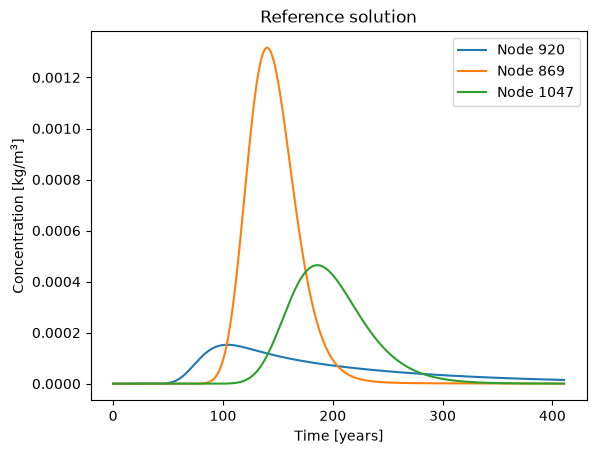

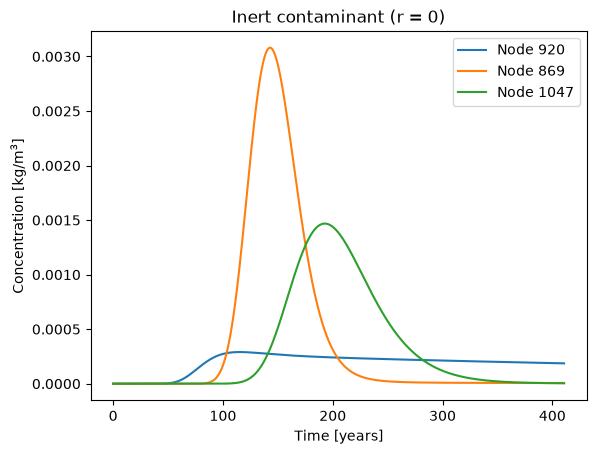

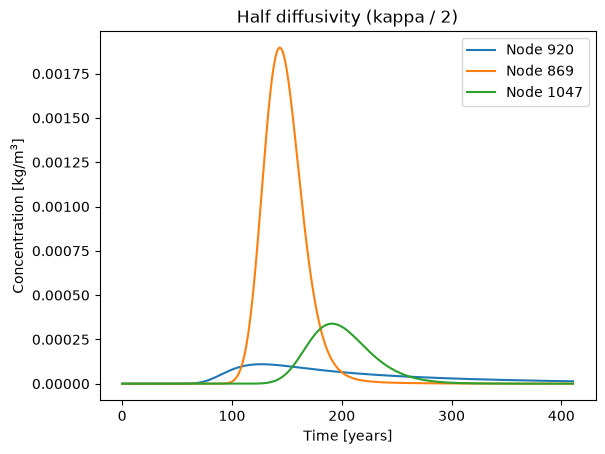

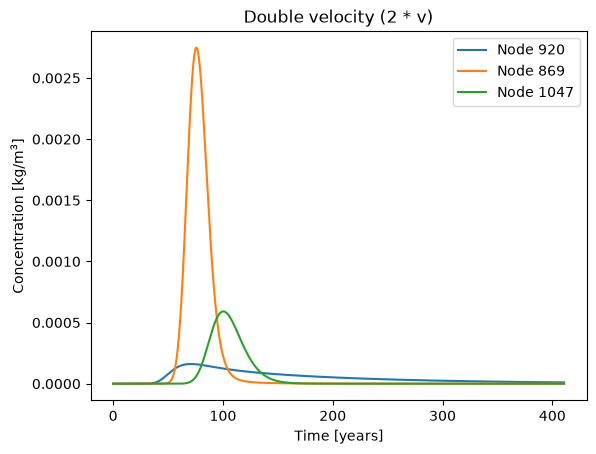

In [7]:
def plot_time_series(concentrations, nodes, dt_days, title):
    plt.figure()
    ts = dt_days/365.25 * np.arange(0,len(concentrations))
    for i in nodes:
        plt.plot(ts, concentrations[:,i],label='Node '+str(i))
    plt.ylabel('Concentration [kg/m$^3$]')
    plt.xlabel('Time [years]')
    plt.title(title)
    plt.legend()
    plt.show()

dt_days = 50

plot_time_series(concentrations, measurement_nodes, dt_days, 'Reference solution')

# 1. Inert (r = 0)
c_inert = simulate(velocities, reaction_rate=0)
plot_time_series(c_inert, measurement_nodes, dt_days, 'Inert contaminant (r = 0)')

# 2. Halve diffusiviteit (kappa / 2)
c_half_diff = simulate(velocities, diffusivity=1e-7)
plot_time_series(c_half_diff, measurement_nodes, dt_days, 'Half diffusivity (kappa / 2)')

# 3. Dubbele snelheid (2 * v)
c_double_vel = simulate(velocities * 2)
plot_time_series(c_double_vel, measurement_nodes, dt_days, 'Double velocity (2 * v)')

## Total mass of pollutant

The total mass in the system can be defined as an integral. 

$$
m = \int c\,\mathrm{d}\Omega
$$

In the function, there are routines for integration of stiffness matrices. Different integration schemes are used. A similar function can be used to evaluate the total mass $m$. 



> **Task 5**
>
> - Look at the different ways integration is performed in `getElementK`, `getElementC` and `getElementM`. Which of these approaches would you use for integrating $c$ over the domain? Reflect on why the different schemes are used for the different matrices. Recall that $c(x,y)$ is defined as $c(x,y) = \mathbf{N}(x,y)\mathbf{c}$ and that the shape functions in $\mathbf{N}$ are linear over each element, i.e. $ N_i(x,y) = A_ix + B_iy + C_i $ where $A_i$, $B_i$ and $C_i$ are constants that are different for each node and element. 
>
> - Implement the function `compute_elem_mass` below according to an appropriate integration scheme
>
> - Inspect the results of how the total mass of the pollutant in the system evolves over time. It should follow an exponential relation for a certain time window. Can you explain to which events in the simulation the bounds of this time window correspond? 


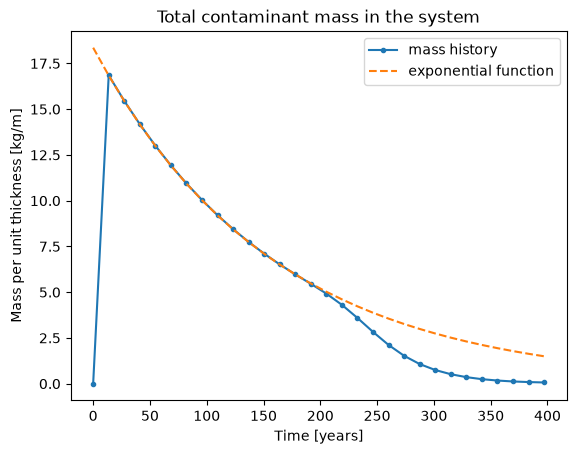

In [8]:
# function to compute the mass in the element
# inputs: node coordinates (n1, n2, n3) concentration vector at those nodes (element_c)
# output: mass integrated over the element 
def compute_elem_mass(n1, n2, n3, element_c):
    element_area = get_area(n1, n2, n3)
    centroid = (n1 + n2 + n3) / 3
    N_centroid = evaluate_N_matrix(centroid, n1, n2, n3)
    element_mass = (N_centroid @ element_c)[0] * element_area
    return element_mass

# function to compute the total mass in the system for given concentration vector
def compute_total_mass(concentration, connectivity, nodes):
    mass = 0
    for elnodes in connectivity:
        mass += compute_elem_mass(nodes[elnodes[0]], nodes[elnodes[1]], nodes[elnodes[2]], concentration[elnodes])
    return mass

# function to compute the total mass in the system over time
def compute_mass_evolution(concentrations, connectivity, nodes):
    total_mass = []
    i = 0
    for concentration in concentrations:
        total_mass.append ( compute_total_mass( concentration, connectivity, nodes) )
        i+=1
    return total_mass

skip = 100
dt_days = 50
ts = dt_days / 365.25 * np.arange(0,len(concentrations))
ts_jump = ts[0:-1:skip]
mass_history = compute_mass_evolution(concentrations[0:-1:skip], connectivity, nodes)

qtotal = 5000 * 24 * 60 * 60 * 2e-9 * 40.7 / 2
exponential = qtotal*np.exp(-2e-10*(ts_jump*24*60*60*365.25-2500*24*60*60))

plt.plot(ts_jump, mass_history, '.-', label='mass history')
plt.plot(ts_jump, exponential, '--', label='exponential function')
plt.ylabel('Mass per unit thickness [kg/m]')
plt.xlabel('Time [years]')
plt.title('Total contaminant mass in the system')
plt.legend()
plt.show()


> By Frans van der Meer, Delft University of Technology. CC BY 4.0, more info on the Credits page of Workbook. 